# Week 7 Examples (Python version) - Bruno Cavagnaro

**GRAD 50800 - Data Analytics**

This is a Python translation of `Week_7_Examples.R`. It covers:
1. K-Nearest Neighbors (KNN)
2. Neural Network (binary: setosa vs not setosa)
3. K-Means Clustering
4. Social Network Recommendation (nearest user by Euclidean distance)
5. Sentiment Analysis (document-term matrix + Naive Bayes)

**R → Python mapping**

| R | Python |
|---|---|
| `data(iris)` | `sklearn.datasets.load_iris(as_frame=True)` |
| `caret::createDataPartition(p = 0.8)` | `train_test_split(test_size=0.2, stratify=y)` |
| `class::knn(k = 5)` | `KNeighborsClassifier(n_neighbors=5)` |
| `neuralnet(hidden = 3, linear.output = FALSE)` | `MLPClassifier(hidden_layer_sizes=(3,), activation="logistic")` |
| `caret::confusionMatrix(positive = "1")` | `confusion_matrix` plus a small helper that prints the same statistics |
| `kmeans(centers = 3)` | `KMeans(n_clusters=3)` |
| `apply(..., function(x) sqrt(sum((x - new_user)^2)))` | `numpy.linalg.norm` / `scipy.spatial.distance.cdist` |
| `tm::VCorpus` + `tolower` + `DocumentTermMatrix` | `CountVectorizer(lowercase=True)` |
| `e1071::naiveBayes` | `GaussianNB` (see the note in Section 5) |

The R script also loads `rpart`, `randomForest` and `SnowballC`, but never uses them.

> **Note:** R and Python random number generators differ, so the train/test splits, the neural network's starting weights and the k-means starting centers are different. The results will be close to the R output but not identical.

## Setup: libraries and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, cohen_kappa_score
from scipy.stats import binomtest

# data(iris)
iris_raw = load_iris(as_frame=True)
iris = iris_raw.frame.rename(columns={
    "sepal length (cm)": "Sepal.Length", "sepal width (cm)": "Sepal.Width",
    "petal length (cm)": "Petal.Length", "petal width (cm)": "Petal.Width"})
iris["Species"] = iris_raw.target_names[iris.pop("target")]
FEATURES = ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width"]
iris.head()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Train/test split (80/20, stratified by species)

In [2]:
# set.seed(42); createDataPartition(iris$Species, p = 0.8)
train_data, test_data = train_test_split(iris, test_size=0.2, stratify=iris["Species"], random_state=42)
print("Train:", train_data.shape, "| Test:", test_data.shape)

Train: (120, 5) | Test: (30, 5)


## 1. K-Nearest Neighbors

`class::knn(train, test, cl, k = 5)` classifies each test flower by a majority vote of its 5 nearest training flowers (Euclidean distance on the **raw**, unscaled features). `KNeighborsClassifier(n_neighbors=5)` does the same; its default metric is also Euclidean. One small difference: R breaks voting ties at random, while scikit-learn picks the first class in sorted order.

In [3]:
train_x, test_x = train_data[FEATURES], test_data[FEATURES]
train_y = train_data["Species"]

knn = KNeighborsClassifier(n_neighbors=5)
knn_predictions = knn.fit(train_x, train_y).predict(test_x)
knn_accuracy = accuracy_score(test_data["Species"], knn_predictions)
print("KNN")
print("Accuracy:", round(knn_accuracy, 4))

KNN
Accuracy: 1.0


## 2. Neural Network (setosa = 1, other = 0)

The R code recodes the outcome as binary (`setosa` = 1, else 0) and fits `neuralnet(hidden = 3, linear.output = FALSE)`: one hidden layer of 3 neurons, with **logistic (sigmoid)** activations and a sigmoid output (because `linear.output = FALSE`), so the output is a probability between 0 and 1.

Python equivalent: `MLPClassifier(hidden_layer_sizes=(3,), activation="logistic")`. Its output layer is also a sigmoid for a binary target.

Differences worth knowing:
* `neuralnet` trains with **resilient backpropagation (rprop+)** and minimises the sum of squared errors. `MLPClassifier` uses L-BFGS here (the most stable choice for small datasets) and minimises log-loss.
* Neither the R code nor this version scales the features. Iris features are all in centimetres and on similar ranges, so this works, but in general you should standardise inputs before training a neural network.

In [4]:
iris_nn = iris.copy()
iris_nn["Species"] = np.where(iris_nn["Species"] == "setosa", 1, 0)

# set.seed(123); createDataPartition(iris_nn$Species, p = 0.8)
train_nn, test_nn = train_test_split(iris_nn, test_size=0.2, stratify=iris_nn["Species"], random_state=123)

nn_model = MLPClassifier(hidden_layer_sizes=(3,), activation="logistic", solver="lbfgs",
                         max_iter=2000, random_state=123)
nn_model.fit(train_nn[FEATURES], train_nn["Species"])

# The model outputs probabilities between 0 and 1
nn_predictions_prob = nn_model.predict_proba(test_nn[FEATURES])[:, 1]

# Convert probabilities to classes with a 0.5 threshold
nn_predictions_class = (nn_predictions_prob > 0.5).astype(int)

In [5]:
def caret_confusion_matrix(pred, actual, positive=1):
    # Print a confusion matrix and the main statistics reported by caret::confusionMatrix
    labels = [0, 1]
    cm = confusion_matrix(actual, pred, labels=labels)          # rows = actual, cols = predicted
    table = pd.DataFrame(cm.T, index=pd.Index(labels, name="Prediction"),
                         columns=pd.Index(labels, name="Reference"))   # caret layout
    tn, fp, fn, tp = cm.ravel()
    n = cm.sum()
    acc = (tp + tn) / n
    ci = binomtest(tp + tn, n).proportion_ci(confidence_level=0.95, method="exact")
    nir = max(np.mean(actual == 0), np.mean(actual == 1))           # no-information rate
    p_acc_gt_nir = binomtest(tp + tn, n, nir, alternative="greater").pvalue
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    ppv = tp / (tp + fp) if (tp + fp) else np.nan
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    prev = (tp + fn) / n
    print("Confusion Matrix and Statistics\n")
    print(table, "\n")
    stats = {
        "Accuracy": acc, "95% CI (low)": ci.low, "95% CI (high)": ci.high,
        "No Information Rate": nir, "P-Value [Acc > NIR]": p_acc_gt_nir,
        "Kappa": cohen_kappa_score(actual, pred),
        "Sensitivity": sens, "Specificity": spec, "Pos Pred Value": ppv, "Neg Pred Value": npv,
        "Prevalence": prev, "Detection Rate": tp / n, "Detection Prevalence": (tp + fp) / n,
        "Balanced Accuracy": np.nanmean([sens, spec]),
    }
    for k, v in stats.items():
        print(f"{k:>22}: {v:.4f}")
    print(f"\n{'Positive Class':>22}: {positive}")

print("NEURAL NETWORK")
caret_confusion_matrix(nn_predictions_class, test_nn["Species"].to_numpy(), positive=1)

NEURAL NETWORK
Confusion Matrix and Statistics

Reference    0   1
Prediction        
0           20   0
1            0  10 

              Accuracy: 1.0000
          95% CI (low): 0.8843
         95% CI (high): 1.0000
   No Information Rate: 0.6667
   P-Value [Acc > NIR]: 0.0000
                 Kappa: 1.0000
           Sensitivity: 1.0000
           Specificity: 1.0000
        Pos Pred Value: 1.0000
        Neg Pred Value: 1.0000
            Prevalence: 0.3333
        Detection Rate: 0.3333
  Detection Prevalence: 0.3333
     Balanced Accuracy: 1.0000

        Positive Class: 1


## 3. K-Means Clustering

`kmeans(cluster_data, centers = 3)` groups the 150 flowers into 3 clusters using only the 4 measurements. The species labels are not used. R's default algorithm is Hartigan-Wong with a single random start (`nstart = 1`). scikit-learn uses Lloyd's algorithm with k-means++ initialisation. I use `n_init=10` (10 random starts, keeping the best), which is the more reliable choice and equivalent to `kmeans(..., nstart = 10)` in R.

The R script fits the model but prints nothing about it. The cells below add what `print(kmeans_model)` would show (cluster sizes, centers, within-cluster sum of squares), a cross-tab of clusters against the true species, and a plot.

In [6]:
cluster_data = iris[FEATURES]
kmeans_model = KMeans(n_clusters=3, n_init=10, random_state=42).fit(cluster_data)

print("K-MEANS CLUSTERING")
print("Cluster sizes:", np.bincount(kmeans_model.labels_))
print("\nCluster means:")
print(pd.DataFrame(kmeans_model.cluster_centers_, columns=FEATURES).round(3))
wss = kmeans_model.inertia_
tss = ((cluster_data - cluster_data.mean()) ** 2).to_numpy().sum()
print(f"\n(between_SS / total_SS = {(1 - wss / tss):.1%})")

print("\nClusters vs actual species (extra, not in the R script):")
pd.crosstab(kmeans_model.labels_, iris["Species"], rownames=["cluster"], colnames=["species"])

K-MEANS CLUSTERING
Cluster sizes: [62 50 38]

Cluster means:
   Sepal.Length  Sepal.Width  Petal.Length  Petal.Width
0         5.902        2.748         4.394        1.434
1         5.006        3.428         1.462        0.246
2         6.850        3.074         5.742        2.071

(between_SS / total_SS = 88.4%)

Clusters vs actual species (extra, not in the R script):


species,setosa,versicolor,virginica
cluster,,,
0,0,48,14
1,50,0,0
2,0,2,36


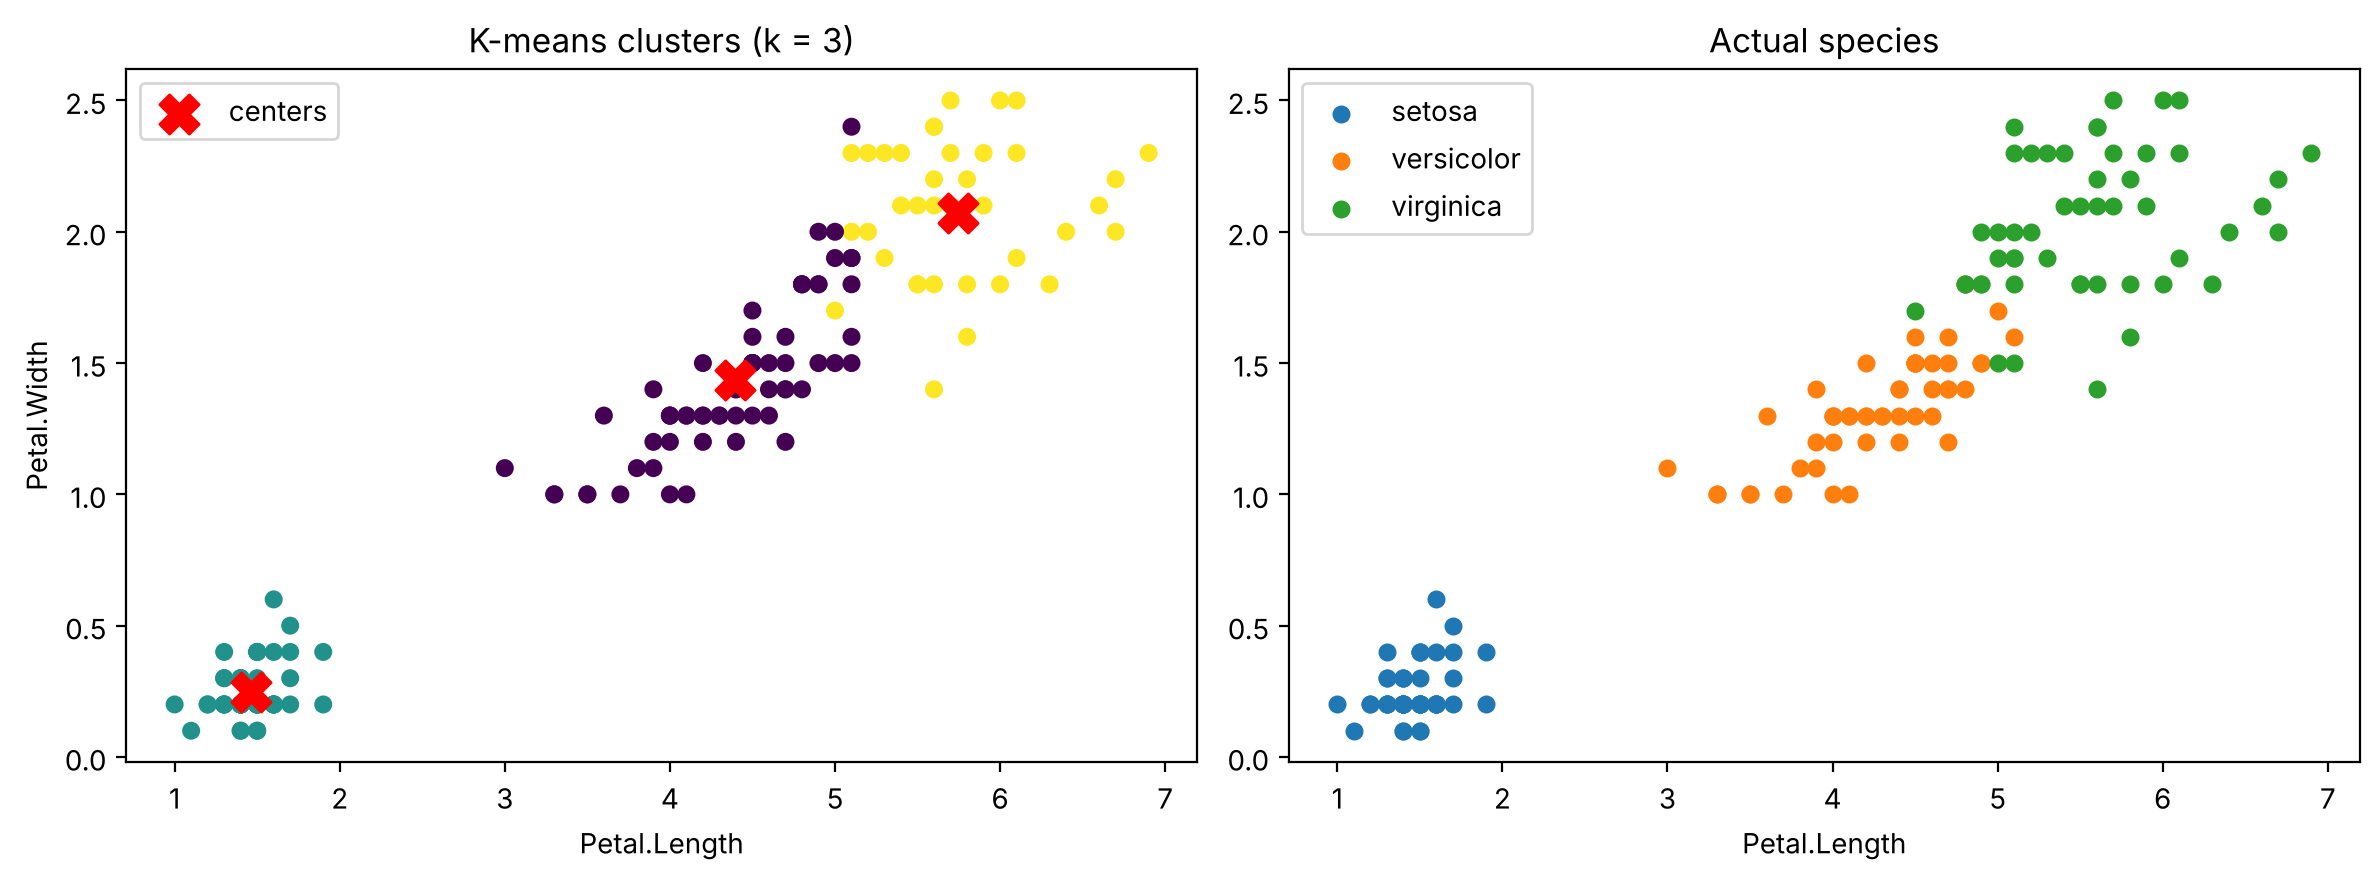

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(iris["Petal.Length"], iris["Petal.Width"], c=kmeans_model.labels_, cmap="viridis", s=30)
axes[0].scatter(kmeans_model.cluster_centers_[:, 2], kmeans_model.cluster_centers_[:, 3],
                c="red", marker="X", s=200, label="centers")
axes[0].set_xlabel("Petal.Length"); axes[0].set_ylabel("Petal.Width")
axes[0].set_title("K-means clusters (k = 3)"); axes[0].legend()
for sp in iris["Species"].unique():
    m = iris["Species"] == sp
    axes[1].scatter(iris.loc[m, "Petal.Length"], iris.loc[m, "Petal.Width"], s=30, label=sp)
axes[1].set_xlabel("Petal.Length"); axes[1].set_title("Actual species"); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Social Network Recommendation

This is a nearest-neighbour recommendation (essentially 1-NN). Each user is described by `Age`, `Activity` and `Interest`, and the new user is matched to the existing user at the smallest **Euclidean distance**.

In [8]:
social_users = pd.DataFrame({"Age": [25, 30, 22, 40], "Activity": [8, 5, 9, 3], "Interest": [7, 6, 8, 4]},
                            index=["UserA", "UserB", "UserC", "UserD"])
new_user = np.array([24, 9, 7])

# apply(social_users, 1, function(x) sqrt(sum((x - new_user)^2)))
distances = np.sqrt(((social_users - new_user) ** 2).sum(axis=1))
recommended_user = distances.idxmin()                       # user_names[which.min(distances)]

print(distances.round(3).to_frame("distance"))
print("\nRecommended User:", recommended_user)

       distance
UserA     1.414
UserB     7.280
UserC     2.236
UserD    17.349

Recommended User: UserA


*Note (extra):* the features are not scaled, so `Age` (range 22-40) dominates the distance more than `Activity` and `Interest` (range 3-9). Standardising the columns first (z-scores) would give each attribute equal weight. Here the answer is still **UserA**, the closest user on age and on the other two attributes.

## 5. Sentiment Analysis

R steps → Python:
1. `VCorpus(VectorSource(texts))` + `tm_map(tolower)` → a list of strings, lowercased by `CountVectorizer(lowercase=True)`.
2. `DocumentTermMatrix(corpus)` → `CountVectorizer().fit_transform(texts)`. **Detail:** by default `tm` keeps only words with **at least 3 characters** (`wordLengths = c(3, Inf)`), so `"I"` is dropped. The token pattern `\b\w{3,}\b` reproduces this.
3. `naiveBayes(Sentiment ~ ., data = sentiment_df)` → `e1071::naiveBayes` treats numeric columns (the word counts) as **Gaussian**, so the faithful translation is `GaussianNB`. For count data, `MultinomialNB` is the standard text classifier, so it is shown as well.
4. As in the R script, accuracy is computed on the **same 6 sentences used for training**, so it measures fit, not generalisation.

In [9]:
texts = ["I love this product", "Amazing experience", "I hate this item",
         "Worst purchase ever", "Fantastic quality", "Very disappointing"]
labels = np.array(["Positive", "Positive", "Negative", "Negative", "Positive", "Negative"])

vectorizer = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b\w{3,}\b")
dtm = vectorizer.fit_transform(texts)
sentiment_df = pd.DataFrame(dtm.toarray(), columns=vectorizer.get_feature_names_out())
sentiment_df["Sentiment"] = labels
sentiment_df

,amazing,disappointing,ever,experience,fantastic,hate,item,love,product,purchase,quality,this,very,worst,Sentiment
0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,Positive
1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,Positive
2,0,0,0,0,0,1,1,0,0,0,0,1,0,0,Negative
3,0,0,1,0,0,0,0,0,0,1,0,0,0,1,Negative
4,0,0,0,0,1,0,0,0,0,0,1,0,0,0,Positive
5,0,1,0,0,0,0,0,0,0,0,0,0,1,0,Negative


In [10]:
X_text = sentiment_df.drop(columns="Sentiment")

sentiment_model = GaussianNB().fit(X_text, labels)            # faithful to e1071::naiveBayes
predictions = sentiment_model.predict(X_text)
print("SENTIMENT ANALYSIS")
print("Sentiment Accuracy (GaussianNB, as in R):", accuracy_score(labels, predictions))

mnb = MultinomialNB().fit(X_text, labels)                     # standard choice for word counts
print("Sentiment Accuracy (MultinomialNB):      ", accuracy_score(labels, mnb.predict(X_text)))

SENTIMENT ANALYSIS
Sentiment Accuracy (GaussianNB, as in R): 1.0
Sentiment Accuracy (MultinomialNB):       1.0


In [11]:
# Extra: score new sentences. Words not seen in training are ignored by the vectorizer.
new_texts = ["I love the quality", "This was the worst experience", "Disappointing item"]
new_X = pd.DataFrame(vectorizer.transform(new_texts).toarray(), columns=X_text.columns)
pd.DataFrame({"text": new_texts, "MultinomialNB": mnb.predict(new_X),
              "P(Positive)": mnb.predict_proba(new_X)[:, list(mnb.classes_).index("Positive")].round(3)})

,text,MultinomialNB,P(Positive)
0,I love the quality,Positive,0.814
1,This was the worst experience,Positive,0.535
2,Disappointing item,Negative,0.215


With only 6 sentences, almost every word appears once, so the model is really a lookup table of "positive" and "negative" words. The new-sentence test shows the problem: *"This was the worst experience"* is classified as **Positive** (P = 0.54). "worst" pulls it toward negative, but "experience" appeared only in the positive sentence "Amazing experience", so the two cancel out and the positive word wins. Likewise, *"not good"* would be scored on "good" alone. Real sentiment models need much more data, and usually stop-word removal, stemming (the `SnowballC` package loaded in the R script, `nltk`'s `SnowballStemmer` in Python) and n-grams to handle negation.

**WEEK 7 EXAMPLES COMPLETED**